# 06 Modely z kamery: pomáhá volitelná kamera a jak si malá síť z kamery stojí proti magnetickým cívkám?

**Otázka (REQ-B01, REQ-B03, REQ-B05; bonusové body úlohy IPP 1).** Zadání dovoluje model, který pracuje z obrazů
rychlé kamery místo 24 magnetických měření, nebo spolu s nimi. Natrénovali jsme **tuto malou síť z kamery 48x64**
(konvoluční síť na snímcích zmenšených na 48x64 pixelů, 811 tisíc parametrů), aby odhadovala stejných 16 cílů tvaru z referenční rekonstrukce ústavu. Ty cíle jsou výstupem té rekonstrukce, ne nezávislým měřením plazmatu, takže síť z kamery posuzujeme podle toho, jak věrně rekonstrukci napodobí, ne podle samotného plazmatu.
Čtyři dílčí otázky:

1. Jak věrně tato malá síť z kamery napodobí referenční rekonstrukci na výbojích, které nikdy neviděla, a jak se to mění s počtem
   učicích výbojů (křivka učení)?
2. Záleží na barvě, nebo stačí černobílá kamera (REQ-B03)?
3. Jak si vede proti magnetické síti **na týchž snímcích a týchž foldech** a pomůže, když dostane oba vstupy
   (REQ-B01)?
4. Jak moc reaguje na pohyb kamery (REQ-B05)?

**Co tento notebook používá a nepoužívá.** Obrazy z kamery ÚFP jsou důvěrné (CON-001) a v gitu nejsou. Sítě
se trénovaly jinde skriptem `analysis/cloud_camera_model.py`; tento notebook čte jen **soubory s výsledky uložené
v gitu** (`results/cloud-camera-*.md` a `.json`), čísla z nich přečte (nic se nepíše ručně), vykreslí je a
odpověď napíše z přečtených hodnot. Nesahá na žádný obraz ani na surový řádek dat. Nic se tu znovu neučí.
Oddíl 6b přidává navazující běh `results/camera-v2.md`: větší síť na snímcích 96x128, učenou s náhodnými posuny, s testem posunu a mapou zakrytí. Tam říkáme „tato síť z kamery 96x128“.

**Pravidla formulace.** Říkáme „tato malá síť z kamery 48x64“, nikdy „kamera“: lepší síť, vyšší rozlišení nebo
víc učicích výbojů by mohly výsledek změnit. Síť z kamery a magnetická síť se porovnávají **jen na týchž
snímcích a foldech** (tabulka v oddílu 5); základní magnetická čísla z notebooku 02 používají všech 149 výbojů a nejsou
pro kameru srovnáním za stejných podmínek.

In [1]:
import json, re, subprocess
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
import re
def cz(text):
    """České číslování v generovaném textu: desetinná čárka místo tečky, mezera jako oddělovač tisíců."""
    text = re.sub(r"(?<![\d,.])([1-9]\d{0,2}),(\d{3})\b", "\\1\u00a0\\2", text)
    return re.sub(r"(?<=\d)\.(?=\d)", ",", text)

# Čtou se jen soubory uložené v gitu: kořen repozitáře se najde podle složky s výsledky a každý soubor otevřený přes
# load_json / load_md se zaznamená a na konci notebooku zkontroluje proti `git ls-files`.
here = Path.cwd().resolve()
repo = next((p for p in [here, *here.parents] if (p / "results" / "cloud-camera-main.json").exists()), None)
if repo is None:
    raise SystemExit("Spusťte z vnitřku repozitáře: results/cloud-camera-main.json nebyl nalezen")
RES = repo / "results"
READ = []

def load_json(name):
    READ.append(f"results/{name}")
    return json.loads((RES / name).read_text(encoding="utf-8"))

def load_md_table(name, table_index=0):
    # první tabulka s rourami ze souboru .md s výsledky jako DataFrame; čísla se převedou na float, prázdné buňky zůstanou prázdné řetězce
    READ.append(f"results/{name}")
    blocks, cur = [], []
    for line in (RES / name).read_text(encoding="utf-8").splitlines():
        if line.startswith("|"):
            cur.append(line)
        elif cur:
            blocks.append(cur); cur = []
    if cur:
        blocks.append(cur)
    rows = [[c.strip() for c in l.strip().strip("|").split("|")] for l in blocks[table_index]]
    head, body = rows[0], [r for r in rows[2:]]
    df = pd.DataFrame(body, columns=head)
    for c in df.columns[1:]:
        if c != "unit":
            df[c] = pd.to_numeric(df[c])
    return df.set_index("target")

def load_md_line(name, prefix):
    READ.append(f"results/{name}")
    for line in (RES / name).read_text(encoding="utf-8").splitlines():
        if line.startswith(prefix):
            return line
    raise KeyError(prefix)

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
C_MAG, C_CAM, C_BOTH, C_GREY = "#2a6fdb", "#e07a5f", "#6a994e", "#7d7d7d"
print("kořen repozitáře nalezen, složka s výsledky:", RES.name, "| soubory s výsledky z kamery v gitu:",
      sorted(p.name for p in RES.glob("cloud-camera-*") if p.suffix in (".md", ".json", ".png")))

kořen repozitáře nalezen, složka s výsledky: results | soubory s výsledky z kamery v gitu: ['cloud-camera-curve.json', 'cloud-camera-curve.md', 'cloud-camera-main.json', 'cloud-camera-main.md', 'cloud-camera-multimodal.json', 'cloud-camera-multimodal.md']


## 1. Protokol (přečtený ze souborů s výsledky)

In [2]:
main = load_json("cloud-camera-main.json")
multi = load_json("cloud-camera-multimodal.json")
curve = load_json("cloud-camera-curve.json")
base = load_json("baseline.json")

PROTO = {
    "velikost obrazu (pixely, výška x šířka)": main["size"],
    "použité snímky": main["frames"],
    "výboje se snímky (ze 149 v magnetických datech)": main["discharges"],
    "krok snímků (každý n-tý snímek výboje)": main["stride"],
    "foldy (dělení po celých výbojích)": main["folds"],
    "testovacích výbojů na fold": main["test_discharges_per_fold"],
    "epoch učení / šířka sítě / semínko": f'{main["epochs"]} / {main["width"]} / {main["seed"]}',
    "parametry (barva / šedá)": f'{main["latency"]["rgb"]["parameters"]:,} / {main["latency"]["grey"]["parameters"]:,}',
}
for k, v in PROTO.items():
    print(f"{k:55s} {v}")
for name, d in (("multimodal", multi), ("curve", curve)):
    same = all(d[k] == main[k] for k in ("size", "frames", "discharges", "stride", "folds", "epochs", "width", "seed", "test_discharges_per_fold"))
    print(f"běh '{name}' používá stejné snímky, foldy a nastavení jako 'main': {same}")
    assert same
print(f"\nprůměr učicích výbojů na fold: {main['discharges']} výbojů minus testovací výboje foldu, asi "
      f"{curve['training']['fraction_1']['discharges']:.1f} (soubor s křivkou)")
print("Cíle z kamery a magnetické vstupy pro každý snímek jsou hodnoty z dat rovnováhy interpolované v čase uvnitř "
      "téhož výboje; síť z kamery vidí jen obraz, magnetická síť jen 24 signálů cívek.")

velikost obrazu (pixely, výška x šířka)                 48x64
použité snímky                                          14520
výboje se snímky (ze 149 v magnetických datech)         78
krok snímků (každý n-tý snímek výboje)                  8
foldy (dělení po celých výbojích)                       5
testovacích výbojů na fold                              [16, 16, 15, 16, 15]
epoch učení / šířka sítě / semínko                      12 / 16 / 0
parametry (barva / šedá)                                811,328 / 811,040
běh 'multimodal' používá stejné snímky, foldy a nastavení jako 'main': True
běh 'curve' používá stejné snímky, foldy a nastavení jako 'main': True

průměr učicích výbojů na fold: 78 výbojů minus testovací výboje foldu, asi 62.4 (soubor s křivkou)
Cíle z kamery a magnetické vstupy pro každý snímek jsou hodnoty z dat rovnováhy interpolované v čase uvnitř téhož výboje; síť z kamery vidí jen obraz, magnetická síť jen 24 signálů cívek.


## 2. Samotná tato malá síť z kamery 48x64 (5 foldů po výbojích)

Průměrná absolutní chyba (MAE) přes 5 foldů v uvedené jednotce a nRMSE = RMSE dělené rozptylem (směrodatnou odchylkou)
daného cíle, aby se cíle v kA, mm a bez jednotky daly dát na jednu stupnici. `± SD` je směrodatná odchylka
MAE přes 5 foldů (jen 15 nebo 16 testovacích výbojů na fold).

In [3]:
t_main = load_md_table("cloud-camera-main.md")
UNIT = t_main["unit"].to_dict()
TARGETS = [t for t in t_main.index if t != "is_limited"]          # 15 regresních cílů; is_limited je klasifikace 0/1
acc_line = load_md_line("cloud-camera-main.md", "is_limited accuracy")
ACC_MAIN = dict(re.findall(r"(rgb|grey) ([0-9.]+)", acc_line))

def sd(res, chan, tgt):
    return res["results"][chan][tgt]["mae_std"]

# tabulky .md jsou zaokrouhlené kopie .json; před použitím json pro směrodatnou odchylku mezi foldy ověříme, že se shodují
for t in t_main.index:
    for chan in ("rgb", "grey"):
        j = main["results"][chan][t]["mae"]
        assert abs(t_main.loc[t, f"{chan} MAE"] - j) <= 0.006 * abs(j) + 1e-9, (t, chan)

tab = pd.DataFrame({
    "unit": t_main["unit"].replace("", "-"),  # cíle bez jednotky: soubor s výsledky nechává buňku prázdnou
    "color MAE": t_main["rgb MAE"],
    "± fold SD": [sd(main, "rgb", t) for t in t_main.index],
    "color nRMSE": t_main["rgb nRMSE"],
}).loc[TARGETS]
print("tato malá síť z kamery 48x64, barevné snímky, 5 foldů, MAE v uvedené jednotce")
print(tab.round(4).to_string())
print(f"\nis_limited (limiterové nebo divertorové plazma), podíl řádků shodných s referenční rekonstrukcí: barva {float(ACC_MAIN['rgb']):.3f}, šedá {float(ACC_MAIN['grey']):.3f}")
rel = np.array([sd(main, "rgb", t) / main["results"]["rgb"][t]["mae"] for t in TARGETS])
print(f"směrodatná odchylka mezi foldy je {rel.min()*100:.0f} až {rel.max()*100:.0f} % MAE: menší rozdíly se nerozliší")

tato malá síť z kamery 48x64, barevné snímky, 5 foldů, MAE v uvedené jednotce
                    unit  color MAE  ± fold SD  color nRMSE
target                                                     
plasma_current        kA    14.6000     6.4662        0.364
R_mag_axis            mm     1.7900     0.4223        0.465
Z_mag_axis            mm     2.4800     0.6121        0.521
elongation             -     0.0160     0.0031        0.122
triangularity          -     0.0090     0.0014        0.159
triangularity_upper    -     0.0095     0.0017        0.276
triangularity_lower    -     0.0130     0.0027        0.150
R_x_point             mm     1.5400     0.3144        0.310
Z_x_point             mm     2.0500     0.8959        0.374
R_strike_point_1      mm     2.2700     0.8286        0.343
Z_strike_point_1      mm     0.7800     0.3584        0.302
R_strike_point_2      mm     2.1100     0.7598        0.378
Z_strike_point_2      mm     0.4210     0.1489        0.386
R_limiter             

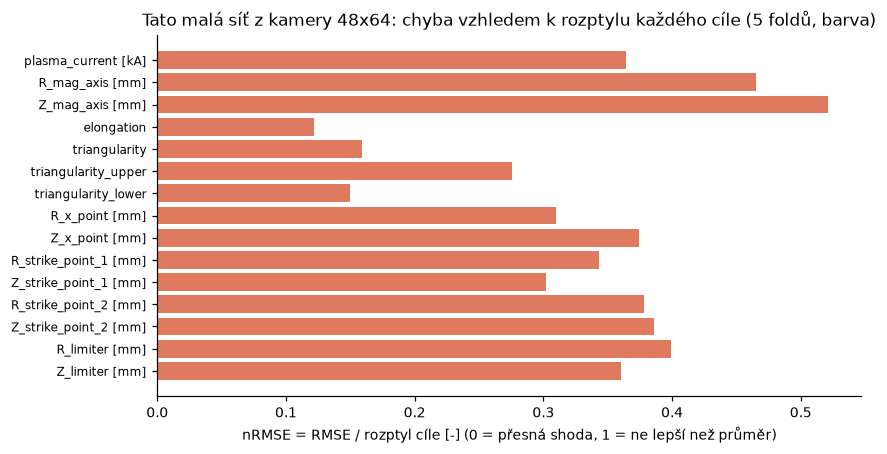

nejmenší relativní chyba: elongation (0.122); největší: Z_mag_axis (0.521)


In [4]:
fig, ax = plt.subplots(figsize=(8, 4.2))
y = np.arange(len(TARGETS))
ax.barh(y, t_main.loc[TARGETS, "rgb nRMSE"], color=C_CAM)
ax.set_yticks(y); ax.set_yticklabels([f"{t} [{UNIT[t]}]" if UNIT[t] else t for t in TARGETS], fontsize=8)
ax.invert_yaxis(); ax.set_xlabel("nRMSE = RMSE / rozptyl cíle [-] (0 = přesná shoda, 1 = ne lepší než průměr)")
ax.set_title("Tato malá síť z kamery 48x64: chyba vzhledem k rozptylu každého cíle (5 foldů, barva)")
plt.tight_layout(); plt.show()
best = t_main.loc[TARGETS, "rgb nRMSE"].idxmin(); worst = t_main.loc[TARGETS, "rgb nRMSE"].idxmax()
print(f"nejmenší relativní chyba: {best} ({t_main.loc[best,'rgb nRMSE']:.3f}); největší: {worst} ({t_main.loc[worst,'rgb nRMSE']:.3f})")

## 3. Křivka učení: kolik učicích výbojů tato malá síť z kamery potřebuje?

Stejná síť, stejných 5 testovacích foldů, vnořené náhodné podmnožiny učicích výbojů každého foldu (barevné snímky). Počet
epoch je pevný, takže menší podmnožiny dostanou i méně kroků optimalizace; část sklonu je tedy z víc kroků, ne
jen z víc dat.

MAE této malé sítě z kamery 48x64 (barva) podle počtu učicích výbojů (průměr přes 5 foldů)
                     4 výbojů  7 výbojů  16 výbojů  31 výbojů  62 výbojů
R_mag_axis [mm]        4.8900     3.890     2.7400     2.3500      1.790
Z_mag_axis [mm]        5.6900     5.300     4.2200     3.3300      2.480
elongation             0.0657     0.046     0.0346     0.0236      0.016
R_x_point [mm]         4.5100     3.760     2.9100     2.2800      1.540
R_limiter [mm]        46.4000    32.300    23.4000    16.8000     12.800
plasma_current [kA]   37.7000    33.600    31.5000    24.9000     14.600
is_limited, podíl řádků shodných s referenční rekonstrukcí: 0.924, 0.936, 0.961, 0.966, 0.976


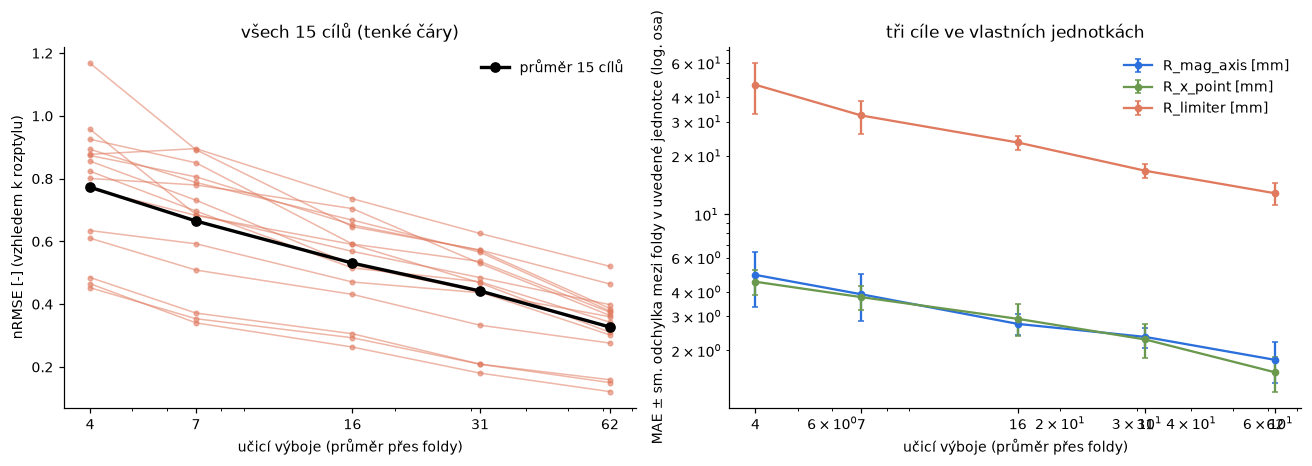

od 31 do 62 učicích výbojů MAE stále klesá u 15 z 15 cílů, o 23 až 41 % (medián 31 %)


In [5]:
t_curve = load_md_table("cloud-camera-curve.md")
FR = ["fraction_0.05", "fraction_0.1", "fraction_0.25", "fraction_0.5", "fraction_1"]
NTRAIN = [curve["training"][f]["discharges"] for f in FR]
# křížová kontrola md proti json a bodu s plnými daty proti běhu 'main' (stejná síť, stejné foldy)
for t in t_curve.index:
    for f in FR:
        assert abs(t_curve.loc[t, f"{f} MAE"] - curve["results"][f][t]["mae"]) <= 0.006 * abs(curve["results"][f][t]["mae"]) + 1e-9
    assert abs(curve["results"]["fraction_1"][t]["mae"] - main["results"]["rgb"][t]["mae"]) <= 0.03 * abs(main["results"]["rgb"][t]["mae"]) + 1e-6, t

show = ["R_mag_axis", "Z_mag_axis", "elongation", "R_x_point", "R_limiter", "plasma_current"]
tab = pd.DataFrame({f"{n:.0f} výbojů": [t_curve.loc[t, f"{f} MAE"] for t in show] for n, f in zip(NTRAIN, FR)},
                   index=[f"{t} [{UNIT[t]}]" if UNIT[t] else t for t in show])
print("MAE této malé sítě z kamery 48x64 (barva) podle počtu učicích výbojů (průměr přes 5 foldů)")
print(tab.to_string())
acc = [curve["results"][f]["is_limited"]["accuracy"] for f in FR]
print("is_limited, podíl řádků shodných s referenční rekonstrukcí:", ", ".join(f"{a:.3f}" for a in acc))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for t in TARGETS:
    ax[0].plot(NTRAIN, [curve["results"][f][t]["nrmse"] for f in FR], marker="o", ms=3, lw=1, color=C_CAM, alpha=0.55)
ax[0].plot(NTRAIN, [np.mean([curve["results"][f][t]["nrmse"] for t in TARGETS]) for f in FR], color="k", lw=2.2, marker="o", label=f"průměr {len(TARGETS)} cílů")
ax[0].set_xscale("log"); ax[0].set_xticks(NTRAIN); ax[0].set_xticklabels([f"{n:.0f}" for n in NTRAIN])
ax[0].xaxis.set_minor_formatter(plt.NullFormatter()); ax[1].xaxis.set_minor_formatter(plt.NullFormatter())
ax[0].set_xlabel("učicí výboje (průměr přes foldy)"); ax[0].set_ylabel("nRMSE [-] (vzhledem k rozptylu)")
ax[0].set_title(f"všech {len(TARGETS)} cílů (tenké čáry)"); ax[0].legend(frameon=False)
for t, c in (("R_mag_axis", C_MAG), ("R_x_point", C_BOTH), ("R_limiter", C_CAM)):
    v = np.array([curve["results"][f][t]["mae"] for f in FR]); s = np.array([curve["results"][f][t]["mae_std"] for f in FR])
    ax[1].errorbar(NTRAIN, v, yerr=s, marker="o", ms=4, capsize=2, color=c, label=f"{t} [{UNIT[t]}]")
ax[1].set_xscale("log"); ax[1].set_yscale("log"); ax[1].set_xticks(NTRAIN); ax[1].set_xticklabels([f"{n:.0f}" for n in NTRAIN])
ax[1].set_xlabel("učicí výboje (průměr přes foldy)"); ax[1].set_ylabel("MAE ± sm. odchylka mezi foldy v uvedené jednotce (log. osa)")
ax[1].set_title("tři cíle ve vlastních jednotkách"); ax[1].legend(frameon=False)
plt.tight_layout(); plt.show()

drop = {t: 1 - curve["results"]["fraction_1"][t]["mae"] / curve["results"]["fraction_0.5"][t]["mae"] for t in TARGETS}
n31, n62 = NTRAIN[3], NTRAIN[4]
print(f"od {n31:.0f} do {n62:.0f} učicích výbojů MAE stále klesá u {sum(d > 0 for d in drop.values())} z {len(TARGETS)} cílů, "
      f"o {min(drop.values())*100:.0f} až {max(drop.values())*100:.0f} % (medián {np.median(list(drop.values()))*100:.0f} %)")

Čtení křivky: chyba stále klesá i u největší velikosti, takže v testovaném rozsahu žádnou plošinu nevidíme. Protože je počet epoch pevný, menší podmnožiny
dostávají i méně kroků, takže část sklonu jsou kroky učení navíc a křivka neukazuje, že by samotné další výboje pomohly. Neříká ani, jak by vypadala za
počtem výbojů, které mají snímky; to je extrapolace, kterou neděláme. Magnetická křivka učení se tu nekreslí: magnetická používá jiné výboje a
řádky, takže její položení vedle této by nebylo srovnání za stejných podmínek (viz `results/robustness-findings.md`, oddíl 2).

## 4. Barva proti černobílé (REQ-B03)

Stejná síť učená na barevných a na šedých snímcích, stejné foldy a semínko. Rozdíl se počítá, jen když je větší
než směrodatná odchylka MAE mezi foldy.

                    unit  color_MAE  gray_MAE  gray_minus_color  gap_over_fold_SD
target                                                                           
plasma_current        kA    14.6014   14.0342           -0.5672           -0.0877
R_mag_axis            mm     1.7879    1.7039           -0.0840           -0.1989
Z_mag_axis            mm     2.4786    2.4020           -0.0766           -0.1049
elongation             -     0.0160    0.0162            0.0002            0.0503
triangularity          -     0.0089    0.0085           -0.0004           -0.2827
triangularity_upper    -     0.0095    0.0089           -0.0006           -0.2860
triangularity_lower    -     0.0130    0.0125           -0.0005           -0.1739
R_x_point             mm     1.5428    1.5045           -0.0383           -0.0939
Z_x_point             mm     2.0494    2.1752            0.1258            0.1379
R_strike_point_1      mm     2.2711    2.2513           -0.0198           -0.0239
Z_strike_point_1

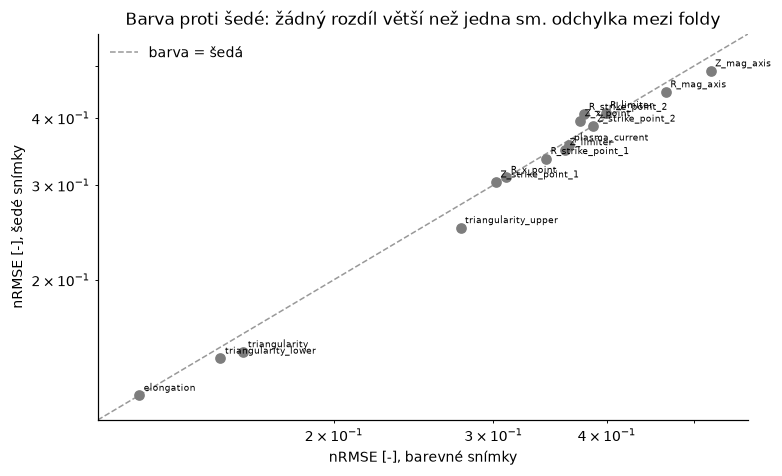

In [6]:
rows = []
for t in TARGETS:
    c, g = main["results"]["rgb"][t], main["results"]["grey"][t]
    gap = g["mae"] - c["mae"]
    rows.append(dict(target=t, unit=UNIT[t] or "-", color_MAE=c["mae"], gray_MAE=g["mae"], gray_minus_color=gap,
                     gap_over_fold_SD=gap / max(c["mae_std"], g["mae_std"])))
cg = pd.DataFrame(rows).set_index("target")
print(cg.round(4).to_string())
n_unres = int((cg["gap_over_fold_SD"].abs() < 1).sum())
print(f"\n{n_unres} z {len(TARGETS)} cílů se liší o méně než jednu směrodatnou odchylku mezi foldy; největší rozdíl je {cg['gap_over_fold_SD'].abs().max():.2f} sm. odchylky "
      f"({cg['gap_over_fold_SD'].abs().idxmax()}). is_limited, podíl řádků shodných s referenční rekonstrukcí: barva {float(ACC_MAIN['rgb']):.3f}, šedá {float(ACC_MAIN['grey']):.3f}")
lat = main["latency"]
print(f"čas modelu na snímek (CPU, medián, jen model): barva {lat['rgb']['single_frame_cpu_ms_median']:.2f} ms, šedá {lat['grey']['single_frame_cpu_ms_median']:.2f} ms")

fig, ax = plt.subplots(figsize=(7.2, 4.4))
lim = [min(t_main.loc[TARGETS, "rgb nRMSE"].min(), t_main.loc[TARGETS, "grey nRMSE"].min()) * 0.9,
       max(t_main.loc[TARGETS, "rgb nRMSE"].max(), t_main.loc[TARGETS, "grey nRMSE"].max()) * 1.1]
ax.plot(lim, lim, color="#999", lw=1, ls="--", label="barva = šedá")
ax.scatter(t_main.loc[TARGETS, "rgb nRMSE"], t_main.loc[TARGETS, "grey nRMSE"], color=C_GREY, zorder=3)
for t in TARGETS:
    ax.annotate(t, (t_main.loc[t, "rgb nRMSE"], t_main.loc[t, "grey nRMSE"]), fontsize=6, xytext=(3, 3), textcoords="offset points")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("nRMSE [-], barevné snímky"); ax.set_ylabel("nRMSE [-], šedé snímky"); ax.legend(frameon=False)
ax.set_title("Barva proti šedé: " + ("žádný rozdíl větší než jedna sm. odchylka mezi foldy" if n_unres == len(TARGETS) else f"{len(TARGETS) - n_unres} rozdílů větších než jedna sm. odchylka mezi foldy"))
plt.tight_layout(); plt.show()

## 5. Tato malá síť z kamery proti magnetické síti, na týchž snímcích a foldech (REQ-B01)

Tři modely, učené přesně na týchž snímcích (oddíl 1) a testované na týchž výbojích v každém foldu:

- **magnetický**: základní MLP (`fit_mlp`, 60 epoch) s 24 signály cívek interpolovanými na tyto snímky;
- **kamera**: tato malá síť z kamery 48x64 (jen obraz);
- **kamera + magnetický**: jedna síť, která bere obraz i 24 signálů cívek.

Tento magnetický srovnávací model se učí jen na snímcích výbojů, které mají kameru, takže je slabší než základ z notebooku 02
(který se učí asi na 119 výbojích). To je cena srovnání za stejných podmínek.

MAE v uvedené jednotce, průměr přes týchž 5 foldů a tytéž snímky (sloupce 'magnetic', 'camera', 'camera_plus_magnetic')
                    unit  magnetic   camera  camera_plus_magnetic  camera_over_magnetic  both_over_magnetic
target                                                                                                     
plasma_current        kA    1.4700  14.6000                2.3000                9.9320              1.5646
R_mag_axis            mm    0.5890   1.7900                1.5400                3.0390              2.6146
Z_mag_axis            mm    0.4950   2.4800                1.1300                5.0101              2.2828
elongation             -    0.0077   0.0160                0.0131                2.0752              1.6991
triangularity          -    0.0039   0.0090                0.0069                2.3127              1.7829
triangularity_upper    -    0.0034   0.0095                0.0064                2.7449              1.8667
triangularity_lo

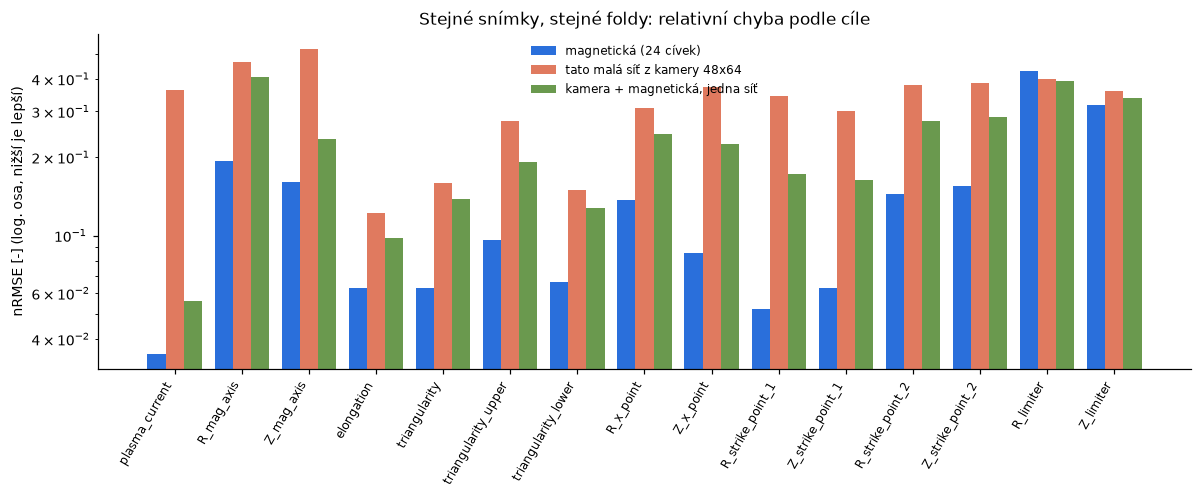

In [7]:
t_mm = load_md_table("cloud-camera-multimodal.md")
acc_mm = dict(re.findall(r"(magnetic|camera\+magnetic|camera) ([0-9.]+)", load_md_line("cloud-camera-multimodal.md", "is_limited accuracy")))
for t in t_mm.index:
    for key, col in (("magnetic", "magnetic"), ("camera", "camera"), ("camera+magnetic", "camera+magnetic")):
        j = multi["results"][key][t]["mae"]
        assert abs(t_mm.loc[t, f"{col} MAE"] - j) <= 0.006 * abs(j) + 1e-9, (t, key)

def msd(key, t):
    return multi["results"][key][t]["mae_std"]

rows = []
for t in TARGETS:
    m, c, b = (t_mm.loc[t, f"{k} MAE"] for k in ("magnetic", "camera", "camera+magnetic"))
    rows.append(dict(target=t, unit=UNIT[t] or "-", magnetic=m, camera=c, camera_plus_magnetic=b,
                     camera_over_magnetic=c / m, both_over_magnetic=b / m,
                     nRMSE_magnetic=t_mm.loc[t, "magnetic nRMSE"], nRMSE_camera=t_mm.loc[t, "camera nRMSE"], nRMSE_both=t_mm.loc[t, "camera+magnetic nRMSE"]))
cmp_ = pd.DataFrame(rows).set_index("target")
print("MAE v uvedené jednotce, průměr přes týchž 5 foldů a tytéž snímky (sloupce 'magnetic', 'camera', 'camera_plus_magnetic')")
print(cmp_[["unit", "magnetic", "camera", "camera_plus_magnetic", "camera_over_magnetic", "both_over_magnetic"]].round(4).to_string())
print(f"\nis_limited, podíl řádků shodných s referenční rekonstrukcí: magnetic {float(acc_mm['magnetic']):.3f}, camera {float(acc_mm['camera']):.3f}, camera+magnetic {float(acc_mm['camera+magnetic']):.3f}")

fig, ax = plt.subplots(figsize=(11, 4.6))
x = np.arange(len(TARGETS)); w = 0.27
for i, (k, col, lab) in enumerate((("magnetic", C_MAG, "magnetická (24 cívek)"), ("camera", C_CAM, "tato malá síť z kamery 48x64"), ("camera+magnetic", C_BOTH, "kamera + magnetická, jedna síť"))):
    ax.bar(x + (i - 1) * w, [t_mm.loc[t, f"{k} nRMSE"] for t in TARGETS], w, color=col, label=lab)
ax.set_yscale("log"); ax.set_xticks(x); ax.set_xticklabels(TARGETS, rotation=60, ha="right", fontsize=8)
ax.set_ylabel("nRMSE [-] (log. osa, nižší je lepší)")
ax.set_title("Stejné snímky, stejné foldy: relativní chyba podle cíle"); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

In [8]:
# který model je u kterého cíle lepší a je rozdíl větší než směrodatná odchylka mezi foldy u obou modelů?
def clear_winner(t, a, b):
    ma, mb = multi["results"][a][t]["mae"], multi["results"][b][t]["mae"]
    return (ma < mb) and (mb - ma > max(msd(a, t), msd(b, t)))

cam_beats_mag = [t for t in TARGETS if cmp_.loc[t, "camera"] < cmp_.loc[t, "magnetic"]]
cam_clear = [t for t in TARGETS if clear_winner(t, "camera", "magnetic")]
mag_clear = [t for t in TARGETS if clear_winner(t, "magnetic", "camera")]
both_beats_mag = [t for t in TARGETS if cmp_.loc[t, "camera_plus_magnetic"] < cmp_.loc[t, "magnetic"]]
both_clear_mag = [t for t in TARGETS if clear_winner(t, "camera+magnetic", "magnetic")]
mag_clear_both = [t for t in TARGETS if clear_winner(t, "magnetic", "camera+magnetic")]
both_beats_cam_lim = [t for t in ("R_limiter", "Z_limiter") if clear_winner(t, "camera+magnetic", "camera")]
ratio_nr = (cmp_["nRMSE_camera"] / cmp_["nRMSE_magnetic"]).drop(["R_limiter", "Z_limiter"])
print(f"kamera má nižší MAE než magnetická síť u {len(cam_beats_mag)} z {len(TARGETS)} cílů: {cam_beats_mag}")
print(f"  ... a rozdíl přesahuje sm. odchylku mezi foldy u obou modelů u: {cam_clear}")
print(f"magnetická je jednoznačně lepší (rozdíl > obě sm. odchylky) u {len(mag_clear)} cílů; u zbývajících {len(TARGETS) - len(mag_clear) - len(cam_clear)} se obě nerozliší")
print(f"u {len(ratio_nr)} cílů kromě bodu limiteru je nRMSE kamery {ratio_nr.min():.1f} až {ratio_nr.max():.1f}krát nRMSE magnetické sítě")
print(f"kamera + magnetická v jedné síti porazí samotnou magnetickou u {len(both_beats_mag)} cílů {both_beats_mag}, jednoznačně u {both_clear_mag}")
print(f"samotná magnetická jednoznačně porazí kameru + magnetickou u {len(mag_clear_both)} cílů: {mag_clear_both}")
print(f"kamera + magnetická jednoznačně porazí samotnou kameru v bodě limiteru u: {both_beats_cam_lim or 'žádného cíle limiteru'}")

kamera má nižší MAE než magnetická síť u 2 z 15 cílů: ['R_limiter', 'Z_limiter']
  ... a rozdíl přesahuje sm. odchylku mezi foldy u obou modelů u: ['R_limiter']
magnetická je jednoznačně lepší (rozdíl > obě sm. odchylky) u 13 cílů; u zbývajících 1 se obě nerozliší
u 13 cílů kromě bodu limiteru je nRMSE kamery 1.9 až 10.4krát nRMSE magnetické sítě
kamera + magnetická v jedné síti porazí samotnou magnetickou u 2 cílů ['R_limiter', 'Z_limiter'], jednoznačně u ['R_limiter']
samotná magnetická jednoznačně porazí kameru + magnetickou u 13 cílů: ['plasma_current', 'R_mag_axis', 'Z_mag_axis', 'elongation', 'triangularity', 'triangularity_upper', 'triangularity_lower', 'R_x_point', 'Z_x_point', 'R_strike_point_1', 'Z_strike_point_1', 'R_strike_point_2', 'Z_strike_point_2']
kamera + magnetická jednoznačně porazí samotnou kameru v bodě limiteru u: žádného cíle limiteru


**Fúze váženou pozdní kombinací, realistické (zašuměné) signály cívek, výboje odložené před konečnou volbou, učení s posuny a
mapa zakrytí** byly naplánované v `analysis/cloud_camera_fusion.py` a `analysis/cloud_camera_explain.py`. Další buňka
zjistí, které z nich mají soubor s výsledky uložený v gitu, aby tento notebook napsal „není k dispozici“ místo
mlčení o mezeře.

In [9]:
KNOWN = {"main", "multimodal", "curve"}
PLANNED = {
    "vážená pozdní fúze s magnetickou sítí": "cloud_camera_fusion.py",
    "kamera proti zašuměným signálům cívek (vstupy z equil_data_noisy.csv)": "cloud_camera_fusion.py",
    "hodnoceno na výbojích odložených před konečnou volbou (těch, které mají snímky)": "cloud_camera_fusion.py --locked",
}
extra = {}
for p in sorted(RES.glob("cloud-camera-*.json")):
    d = load_json(p.name)
    if d.get("experiment") not in KNOWN:
        extra[p.name] = d.get("experiment")
if extra:
    print("další soubory s výsledky z kamery nalezené v gitu:", extra)
    for name in extra:
        md_name = name.replace(".json", ".md")
        if (RES / md_name).exists():
            READ.append(f"results/{md_name}")
            display(Markdown((RES / md_name).read_text(encoding="utf-8")))
else:
    print("V gitu není uložen žádný další soubor s výsledky z kamery. Tady nejsou k dispozici (žádné číslo se pro ně neukazuje):")
    for k, v in PLANNED.items():
        print(f"  - {k}   [skript: {v}]")

V gitu není uložen žádný další soubor s výsledky z kamery. Tady nejsou k dispozici (žádné číslo se pro ně neukazuje):
  - vážená pozdní fúze s magnetickou sítí   [skript: cloud_camera_fusion.py]
  - kamera proti zašuměným signálům cívek (vstupy z equil_data_noisy.csv)   [skript: cloud_camera_fusion.py]
  - hodnoceno na výbojích odložených před konečnou volbou (těch, které mají snímky)   [skript: cloud_camera_fusion.py --locked]


## 6. Kamera, která se pohybuje (REQ-B05)

Tato malá síť z kamery se učila na nehybném obraze a testovala se na snímcích posunutých o 1, 2 nebo 4 uložené pixely
(jeden uložený pixel je 1/64 šířky snímku) ve směru x nebo y, nebo otočených kolem středu obrazu o 1, 2 nebo 5 stupňů. Poměr je
MAE na pohnutých snímcích dělené MAE na nepohnutých snímcích téže sítě (barva; šedá síť se chová
stejně, jak ověří další buňka). Model *učený* s náhodnými posuny je jiná, větší síť a je v oddíle 6b.

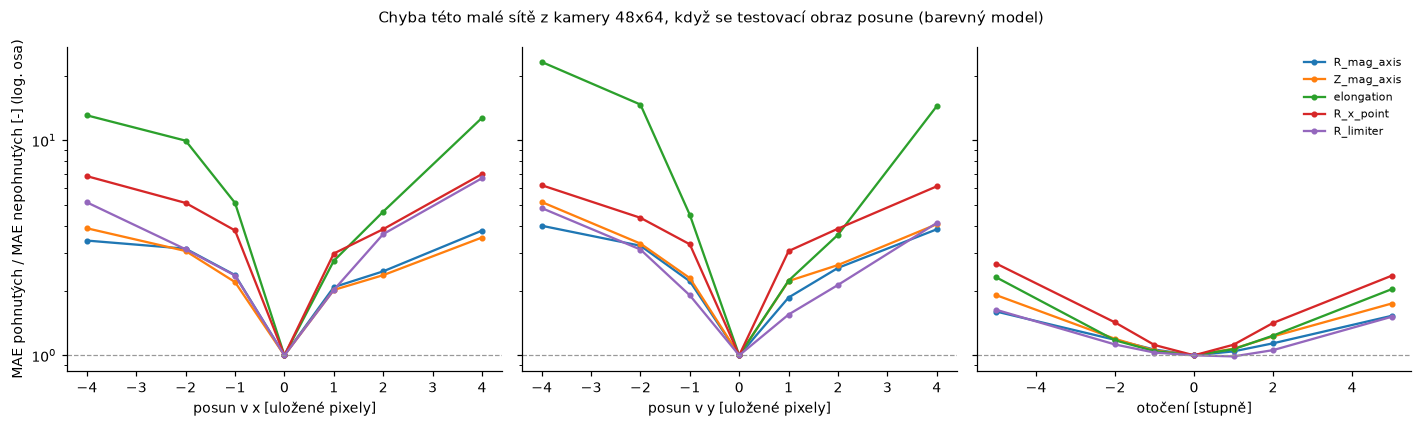

nejhorší poměr přes směry (posun: x a y, + a -; otočení: + a -), barevný model
            shift 1  shift 4  rotate 1  rotate 2  rotate 5
R_mag_axis     2.36     4.01      1.06      1.18      1.60
Z_mag_axis     2.29     5.17      1.07      1.22      1.90
elongation     5.12    23.16      1.07      1.23      2.30
R_x_point      3.81     6.97      1.12      1.42      2.67
R_limiter      2.35     6.66      1.03      1.12      1.63
is_limited, podíl řádků shodných s referenční rekonstrukcí: {'clean': 0.975, 'shift_x=+1': 0.962, 'shift_x=+4': 0.738, 'rotate=+5': 0.966}
šedá proti barvě, posun o 1 pixel: mediánový relativní rozdíl nejhoršího poměru 5 %


In [10]:
sw = main["sweeps"]
SENS = ["R_mag_axis", "Z_mag_axis", "elongation", "R_x_point", "R_limiter"]
def ratio(chan, key, t):
    return sw[chan][key][t]["mae"] / sw[chan]["clean"][t]["mae"]

shifts = [-4, -2, -1, 1, 2, 4]
rots = [-5, -2, -1, 1, 2, 5]
fig, ax = plt.subplots(1, 3, figsize=(13, 3.9), sharey=True)
for a, (ttl, keyf, xs) in zip(ax, (("posun v x [uložené pixely]", lambda s: f"shift_x={s:+d}", shifts),
                                   ("posun v y [uložené pixely]", lambda s: f"shift_y={s:+d}", shifts),
                                   ("otočení [stupně]", lambda s: f"rotate={s:+d}", rots))):
    for t in SENS:
        xx = sorted(xs + [0])
        a.plot(xx, [1.0 if s == 0 else ratio("rgb", keyf(s), t) for s in xx], marker="o", ms=3, label=t)
    a.axhline(1, color="#999", lw=0.8, ls="--"); a.set_yscale("log"); a.set_xlabel(ttl)
ax[0].set_ylabel("MAE pohnutých / MAE nepohnutých [-] (log. osa)"); ax[2].legend(frameon=False, fontsize=7)
fig.suptitle("Chyba této malé sítě z kamery 48x64, když se testovací obraz posune (barevný model)", fontsize=10)
plt.tight_layout(); plt.show()

def worst(chan, kind, mag):
    if kind == "shift":
        keys = [f"shift_{ax_}={s:+d}" for ax_ in "xy" for s in (-mag, mag)]
    else:
        keys = [f"rotate={s:+d}" for s in (-mag, mag)]
    return {t: max(ratio(chan, k, t) for k in keys) for t in TARGETS}

tab = pd.DataFrame({f"{kind} {mag}": worst("rgb", kind, mag) for kind, mag in (("shift", 1), ("shift", 4), ("rotate", 1), ("rotate", 2), ("rotate", 5))})
print("nejhorší poměr přes směry (posun: x a y, + a -; otočení: + a -), barevný model")
print(tab.loc[SENS].round(2).to_string())
# čtení níže se tady kontroluje, neopisuje se z paměti
assert (tab.loc[SENS, "shift 1"] > 2).all() and (tab.loc[SENS, "rotate 2"] < tab.loc[SENS, "shift 1"]).all()
acc_s = {k: sw["rgb"][k]["is_limited"]["accuracy"] for k in ("clean", "shift_x=+1", "shift_x=+4", "rotate=+5")}
print("is_limited, podíl řádků shodných s referenční rekonstrukcí:", {k: round(v, 3) for k, v in acc_s.items()})
grey_same = np.median([abs(np.log(worst("grey", "shift", 1)[t] / worst("rgb", "shift", 1)[t])) for t in TARGETS])
print(f"šedá proti barvě, posun o 1 pixel: mediánový relativní rozdíl nejhoršího poměru {np.expm1(grey_same)*100:.0f} %")

Čtení: tato síť odhaduje absolutní polohy v obraze, takže pohybující se kamera vypadá jako pohybující se plazma.
V tabulce výše posun o jeden uložený pixel už násobí chybu každého zobrazeného cíle více než dvěma, nejvíc trpí parametry tvaru
a otočení o 2 stupně znamená mnohem méně než posun o jeden pixel. Oddíl 6b zkouší, jestli učení s náhodnými posuny tento efekt odstraní, na jiné a větší síti.

## 6b. Kamera v2: větší síť 96x128, augmentace, test posunu, mapa zakrytí (REQ-B05, REQ-B07)

Oddíl 6 ukázal, že tato malá síť z kamery 48x64 silně reaguje na pohyb kamery. Navazující běh `results/camera-v2.md`
(jeho protokol byl uložen před během) učí **tuto síť z kamery 96x128**: šedé snímky zmenšené na 96x128 pixelů, stejné uspořádání jako
malá síť, ale dvakrát širší (šířka 32), 20 epoch, každý 4. snímek učicích výbojů pro učení a každý 8. snímek
odložených výbojů pro test (testovací snímky malé sítě), stejných 5 foldů po výbojích, žádné výboje stranou. Dvě větve:
**A** jak je popsáno, **B** s náhodnými posuny až o 2 pixely a otočeními až o 2 stupně přidanými ke každému učicímu snímku. Tabulky
dávají obě vedle malé sítě a vedle **magnetické sítě** (vícevrstvý perceptron na 24 signálech cívek) učené na týchž učicích snímcích
a hodnocené na týchž testovacích snímcích týchž foldů. Všechny cíle jsou referenční rekonstrukce ústavu, takže každé číslo je shoda s ní,
ne se samotným plazmatem. Jedno semínko na větev, plus druhé semínko větve A, aby bylo vidět, jak moc se táž síť mezi semínky mění. Sítě se učily na GPU od Applu skriptem `analysis/camera_v2.py`; tento notebook čte jen uložený soubor s výsledky.

In [11]:
V2 = "camera-v2.md"
READ.append(f"results/{V2}")
READ.append("results/camera-v2-occlusion.png")
v2_text = (RES / V2).read_text(encoding="utf-8")

def md_tables(text):
    # každá tabulka s rourami z textu .md s výsledky jako seznam řádků buněk (včetně hlavičky a oddělovače)
    tables, cur = [], []
    for line in text.splitlines():
        if line.startswith("|"):
            cur.append([c.strip() for c in line.strip().strip("|").split("|")])
        elif cur:
            tables.append(cur); cur = []
    if cur:
        tables.append(cur)
    return tables

def md_table(header, rows):
    return "\n".join(["| " + " | ".join(header) + " |", "|" + "---|" * len(header)] + ["| " + " | ".join(r) + " |" for r in rows])

tabs = md_tables(v2_text)
head = tabs[0][0]
assert head[2].startswith("magnetic MLP") and head[4].startswith("old small network") and head[6].startswith("this 96x128 network, A") and head[8].startswith("this 96x128 network, B"), head
t_res, t_move, t_occ = tabs[0][2:], tabs[1][2:], tabs[2][2:]
V2COLS = ["mag MAE", "mag nRMSE", "old MAE", "old nRMSE", "A MAE", "A nRMSE", "B MAE", "B nRMSE"]
v2 = pd.DataFrame([[float(c) for c in r[2:10]] for r in t_res], index=[r[0] for r in t_res], columns=V2COLS)
V2_UNIT = {r[0]: r[1] for r in t_res}
assert list(v2.index) == TARGETS, "cíle v tabulce v2 se liší od oddílu 2"
agree = dict(re.findall(r"(magnetic MLP|old small network|A|B) ([01]\.\d+)", load_md_line(V2, "`is_limited` agreement")))

# malá síť v tabulce v2 musí být ta z oddílu 2 (stejné hodnoty ze souboru až na zaokrouhlení tabulky)
old_json = {t: main["results"]["grey"][t]["mae"] for t in TARGETS}
dev = max(abs(v2.loc[t, "old MAE"] / old_json[t] - 1) for t in TARGETS)
print(f"malá síť v tabulce v2 proti results/cloud-camera-main.json (šedá): největší relativní rozdíl {dev:.2%}")
assert dev < 0.02
print(load_md_line(V2, "Training time per fold"))
print("shoda příznaku limiterový / divertorový s referenční rekonstrukcí:", agree)

malá síť v tabulce v2 proti results/cloud-camera-main.json (šedá): největší relativní rozdíl 0.30%
Training time per fold on the Apple GPU: A 606 s, B 611 s; parameters: A 2,179,888, B 2,179,888.
shoda příznaku limiterový / divertorový s referenční rekonstrukcí: {'magnetic MLP': '0.992', 'old small network': '0.975', 'A': '0.962', 'B': '0.980'}


**MAE proti referenční rekonstrukci, průměr přes 5 foldů, v každém sloupci tytéž testovací snímky** (mm, proud plazmatu v kA, čísla tvaru bez jednotky)

| cíl | jednotka | magnetické MLP | stará malá 48x64 | A: 96x128 | B: 96x128 + posuny | B / stará malá | B / magnetické |
|---|---|---|---|---|---|---|---|
| plasma_current | kA | 1.36 | 14 | 20.4 | 11 | 0.79 | 8.1 |
| R_mag_axis | mm | 0.407 | 1.7 | 2.28 | 1.59 | 0.94 | 3.9 |
| Z_mag_axis | mm | 0.419 | 2.4 | 3.33 | 1.99 | 0.83 | 4.7 |
| elongation | - | 0.0061 | 0.0162 | 0.0278 | 0.0126 | 0.78 | 2.1 |
| triangularity | - | 0.00322 | 0.00855 | 0.0138 | 0.00702 | 0.82 | 2.2 |
| triangularity_upper | - | 0.00308 | 0.00891 | 0.0128 | 0.00757 | 0.85 | 2.5 |
| triangularity_lower | - | 0.00426 | 0.0125 | 0.0209 | 0.0102 | 0.82 | 2.4 |
| R_x_point | mm | 0.335 | 1.5 | 2.19 | 1.36 | 0.91 | 4.1 |
| Z_x_point | mm | 0.24 | 2.18 | 3.11 | 1.62 | 0.74 | 6.8 |
| R_strike_point_1 | mm | 0.25 | 2.25 | 3.24 | 1.86 | 0.83 | 7.4 |
| Z_strike_point_1 | mm | 0.117 | 0.787 | 1.3 | 0.688 | 0.87 | 5.9 |
| R_strike_point_2 | mm | 0.376 | 2.18 | 3.12 | 1.71 | 0.78 | 4.5 |
| Z_strike_point_2 | mm | 0.0844 | 0.416 | 0.628 | 0.336 | 0.81 | 4.0 |
| R_limiter | mm | 12.7 | 13.1 | 18 | 11.6 | 0.89 | 0.9 |
| Z_limiter | mm | 24.3 | 28.7 | 42 | 25 | 0.87 | 1.0 |

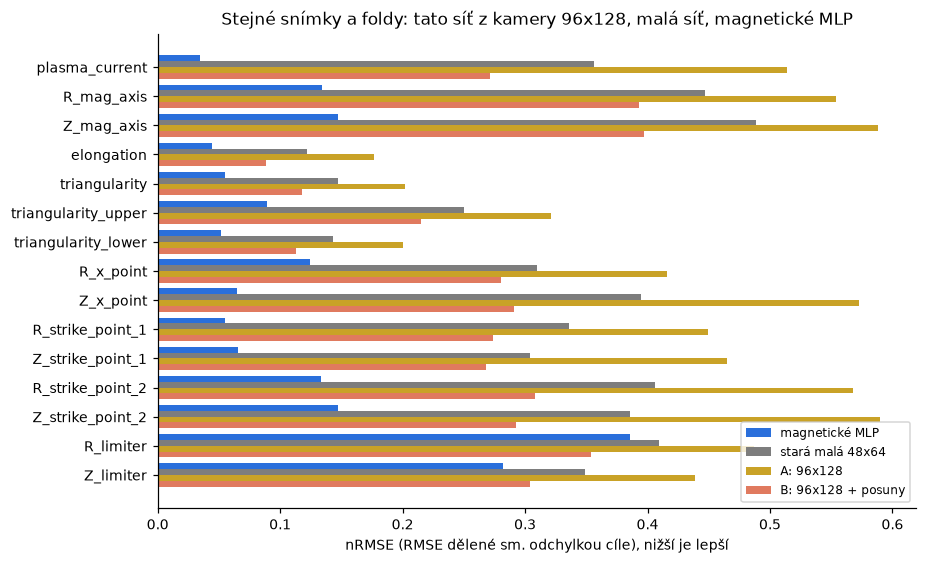

In [12]:
g3 = lambda x: f"{x:.3g}"
rows = [[t, V2_UNIT[t]] + [g3(v2.loc[t, c]) for c in ("mag MAE", "old MAE", "A MAE", "B MAE")]
        + [f"{v2.loc[t, 'B MAE'] / v2.loc[t, 'old MAE']:.2f}", f"{v2.loc[t, 'B MAE'] / v2.loc[t, 'mag MAE']:.1f}"] for t in TARGETS]
display(Markdown("**MAE proti referenční rekonstrukci, průměr přes 5 foldů, v každém sloupci tytéž testovací snímky** (mm, proud plazmatu v kA, čísla tvaru bez jednotky)\n\n"
                 + md_table(["cíl", "jednotka", "magnetické MLP", "stará malá 48x64", "A: 96x128", "B: 96x128 + posuny", "B / stará malá", "B / magnetické"], rows)))

fig, ax = plt.subplots(figsize=(8.5, 5.2))
y = np.arange(len(TARGETS)); h = 0.2
for k, (col, lab, colr) in enumerate([("mag nRMSE", "magnetické MLP", C_MAG), ("old nRMSE", "stará malá 48x64", C_GREY), ("A nRMSE", "A: 96x128", "#c9a227"), ("B nRMSE", "B: 96x128 + posuny", C_CAM)]):
    ax.barh(y + (k - 1.5) * h, v2.loc[TARGETS, col], h, label=lab, color=colr)
ax.set_yticks(y); ax.set_yticklabels(TARGETS); ax.invert_yaxis()
ax.set_xlabel("nRMSE (RMSE dělené sm. odchylkou cíle), nižší je lepší")
ax.set_title("Stejné snímky a foldy: tato síť z kamery 96x128, malá síť, magnetické MLP")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

**C. Testovací snímky posunuté o 1 pixel nebo otočené o 1 stupeň** (poměr chyby na pohnutých snímcích k chybě na nepohnutých, 1,00 = beze změny)

| cíl | A: MAE nepohnutých | A: poměr (nejhorší pohyb) | B: MAE nepohnutých | B: poměr (nejhorší pohyb) |
|---|---|---|---|---|
| plasma_current | 20.4 | 1.33 (1.74) | 11 | 0.99 (1.02) |
| R_mag_axis | 2.28 | 1.33 (1.59) | 1.59 | 0.99 (1.00) |
| Z_mag_axis | 3.33 | 1.33 (1.50) | 1.99 | 1.00 (1.01) |
| elongation | 0.0278 | 1.40 (1.67) | 0.0126 | 0.99 (1.01) |
| R_x_point | 2.19 | 1.68 (2.30) | 1.36 | 0.99 (1.01) |
| R_strike_point_1 | 3.24 | 1.43 (1.66) | 1.86 | 0.99 (1.02) |
| R_limiter | 18 | 1.24 (1.46) | 11.6 | 1.01 (1.01) |
| Z_limiter | 42 | 1.27 (1.52) | 25 | 1.01 (1.01) |

**D. Mapa zakrytí sítě B** (šedá záplata 16x16 pixelů vždy zakryje jednu část snímku 96x128; nárůst průměrné absolutní chyby)

| cíl | jednotka | chyba bez zakrytí | největší nárůst | u záplaty (řádek, sloupec v px) | mediánový nárůst přes mřížku | záplaty nad polovinou největšího nárůstu |
|---|---|---|---|---|---|---|
| R_mag_axis | mm | 1.59 | 1.26 | (48, 64) | 0.183 | 8 z 48 |
| Z_mag_axis | mm | 1.99 | 1.09 | (48, 48) | 0.169 | 9 z 48 |
| elongation | - | 0.0126 | 0.0291 | (48, 48) | 0.00275 | 3 z 48 |
| R_strike_point_1 | mm | 1.86 | 2.77 | (48, 80) | 0.252 | 2 z 48 |

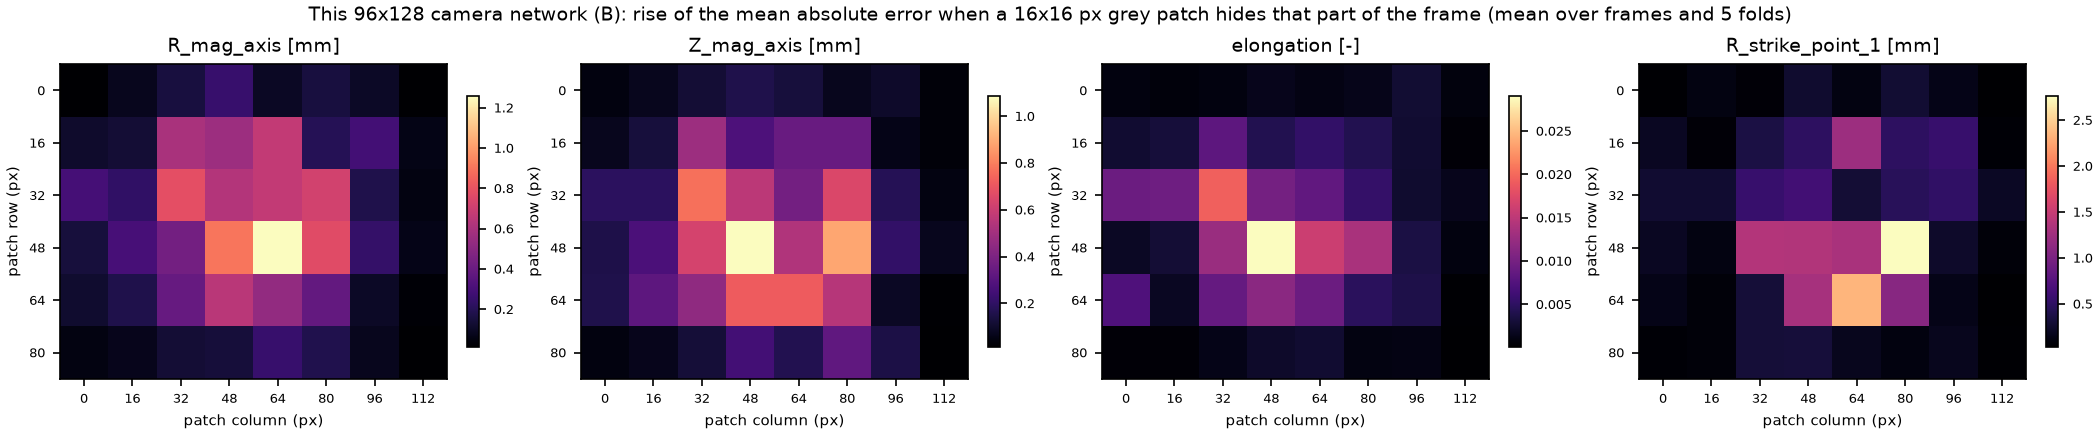

In [13]:
# C: poměr MAE na pohnutých testovacích snímcích k MAE na nepohnutých (průměr přes 6 pohybů: 1 pixel doprava, doleva, dolů, nahoru; 1 stupeň na obě strany)
mv = {}
for r in t_move:
    a, b = re.findall(r"[\d.]+", r[2]), re.findall(r"[\d.]+", r[4])
    mv[r[0]] = dict(A=float(a[0]), A_worst=float(a[1]), B=float(b[0]), B_worst=float(b[1]), A_mae=float(r[1]), B_mae=float(r[3]))
display(Markdown("**C. Testovací snímky posunuté o 1 pixel nebo otočené o 1 stupeň** (poměr chyby na pohnutých snímcích k chybě na nepohnutých, 1,00 = beze změny)\n\n"
                 + md_table(["cíl", "A: MAE nepohnutých", "A: poměr (nejhorší pohyb)", "B: MAE nepohnutých", "B: poměr (nejhorší pohyb)"],
                            [[t, g3(m["A_mae"]), f"{m['A']:.2f} ({m['A_worst']:.2f})", g3(m["B_mae"]), f"{m['B']:.2f} ({m['B_worst']:.2f})"] for t, m in mv.items()])))

# D: mapa zakrytí, souhrnná čísla ze souboru s výsledky a souhrnný obrázek ze souboru (žádný snímek se neukazuje)
occ = {r[0]: dict(unit=r[1], base=float(r[2]), peak=float(r[3]), at=tuple(int(x) for x in re.findall(r"\d+", r[4])), med=float(r[5]),
                  n_half=int(r[6].split()[0]), n_all=int(r[6].split()[2])) for r in t_occ}
display(Markdown("**D. Mapa zakrytí sítě B** (šedá záplata 16x16 pixelů vždy zakryje jednu část snímku 96x128; nárůst průměrné absolutní chyby)\n\n"
                 + md_table(["cíl", "jednotka", "chyba bez zakrytí", "největší nárůst", "u záplaty (řádek, sloupec v px)", "mediánový nárůst přes mřížku", "záplaty nad polovinou největšího nárůstu"],
                            [[t, o["unit"], g3(o["base"]), g3(o["peak"]), str(o["at"]), g3(o["med"]), f"{o['n_half']} z {o['n_all']}"] for t, o in occ.items()])))
from IPython.display import Image
display(Image(filename=str(RES / "camera-v2-occlusion.png")))

In [14]:
# druhé semínko větve A (táž síť a nastavení, jiné náhodné semínko) a jeho test posunu
seed = seed_move = None
for t in tabs[3:]:
    if t[0][:4] == ["target", "unit", "MAE seed 0", "MAE seed 1"]:
        seed = {r[0]: (float(r[2]), float(r[3]), float(r[5].replace("%", "").replace("+", ""))) for r in t[2:]}
    elif t[0][:2] == ["target", "A seed 1: unmoved MAE"]:
        seed_move = {r[0]: (float(r[1]), *map(float, re.findall(r"[\d.]+", r[2]))) for r in t[2:]}      # MAE nepohnutých, poměr, nejhorší pohyb
assert seed is not None and seed_move is not None, "druhé semínko větve A není v souboru s výsledky"
seed_rel = [abs(v[2]) for v in seed.values()]
v2["A1 MAE"] = [seed[t][1] for t in v2.index]
assert max(abs(v2.loc[t, "A MAE"] / seed[t][0] - 1) for t in v2.index) < 0.01      # semínko 0 v tabulce semínek je větev A z hlavní tabulky
display(Markdown("**Větev A, dvě semínka** (táž síť, nastavení a foldy; liší se jen náhodné semínko)\n\n"
                 + md_table(["cíl", "jednotka", "A semínko 0", "A semínko 1", "změna", "stará malá 48x64", "B: 96x128 + posuny"],
                            [[t, V2_UNIT[t], g3(seed[t][0]), g3(seed[t][1]), f"{seed[t][2]:+.0f} %", g3(v2.loc[t, "old MAE"]), g3(v2.loc[t, "B MAE"])] for t in TARGETS])))
print(f"větev A: mezi semínkem 0 a 1 se MAE mění o {min(seed_rel):.0f} až {max(seed_rel):.0f} % (medián {np.median(seed_rel):.0f} %) přes {len(seed)} cílů")
print("test posunu větve A, semínko 1 (poměr, nejhorší pohyb):", {t: (m[1], m[2]) for t, m in seed_move.items()})

**Větev A, dvě semínka** (táž síť, nastavení a foldy; liší se jen náhodné semínko)

| cíl | jednotka | A semínko 0 | A semínko 1 | změna | stará malá 48x64 | B: 96x128 + posuny |
|---|---|---|---|---|---|---|
| plasma_current | kA | 20.4 | 14 | -31 % | 14 | 11 |
| R_mag_axis | mm | 2.28 | 1.57 | -31 % | 1.7 | 1.59 |
| Z_mag_axis | mm | 3.33 | 2.15 | -35 % | 2.4 | 1.99 |
| elongation | - | 0.0278 | 0.0137 | -51 % | 0.0162 | 0.0126 |
| triangularity | - | 0.0138 | 0.00749 | -46 % | 0.00855 | 0.00702 |
| triangularity_upper | - | 0.0128 | 0.00779 | -39 % | 0.00891 | 0.00757 |
| triangularity_lower | - | 0.0209 | 0.0115 | -45 % | 0.0125 | 0.0102 |
| R_x_point | mm | 2.19 | 1.4 | -36 % | 1.5 | 1.36 |
| Z_x_point | mm | 3.11 | 1.77 | -43 % | 2.18 | 1.62 |
| R_strike_point_1 | mm | 3.24 | 1.84 | -43 % | 2.25 | 1.86 |
| Z_strike_point_1 | mm | 1.3 | 0.676 | -48 % | 0.787 | 0.688 |
| R_strike_point_2 | mm | 3.12 | 1.92 | -38 % | 2.18 | 1.71 |
| Z_strike_point_2 | mm | 0.628 | 0.385 | -39 % | 0.416 | 0.336 |
| R_limiter | mm | 18 | 11.6 | -35 % | 13.1 | 11.6 |
| Z_limiter | mm | 42 | 25.5 | -39 % | 28.7 | 25 |

větev A: mezi semínkem 0 a 1 se MAE mění o 31 až 51 % (medián 39 %) přes 15 cílů
test posunu větve A, semínko 1 (poměr, nejhorší pohyb): {'plasma_current': (1.8, 2.34), 'R_mag_axis': (1.74, 2.32), 'Z_mag_axis': (1.66, 2.02), 'elongation': (2.15, 3.28), 'R_x_point': (2.52, 3.65), 'R_strike_point_1': (2.18, 2.8), 'R_limiter': (1.52, 2.0), 'Z_limiter': (1.69, 2.3)}


In [15]:
lim = ["R_limiter", "Z_limiter"]
non_lim = [t for t in TARGETS if t not in lim]
a0_over_old = v2["A MAE"] / v2["old MAE"]
a1_over_old = v2["A1 MAE"] / v2["old MAE"]
b_over_old = v2["B MAE"] / v2["old MAE"]
a1_over_b = v2["A1 MAE"] / v2["B MAE"]
b_over_mag = (v2["B MAE"] / v2["mag MAE"])[non_lim]
a1_over_mag = (v2["A1 MAE"] / v2["mag MAE"])[non_lim]
n_all = len(TARGETS)
a0_worse, a1_better, b_better = int((a0_over_old > 1).sum()), int((a1_over_old < 1).sum()), int((b_over_old < 1).sum())
b_mv_lo, b_mv_hi = min(m["B"] for m in mv.values()), max(m["B"] for m in mv.values())
b_mv_worst = max(m["B_worst"] for m in mv.values())
a_mv_lo, a_mv_hi = min(m["A"] for m in mv.values()), max(m["A"] for m in mv.values())
a1_mv_lo, a1_mv_hi = min(m[1] for m in seed_move.values()), max(m[1] for m in seed_move.values())
for t, o in occ.items():                                      # text níže tvrdí, že největší nárůst je poblíž středu snímku 96x128
    assert 32 <= o["at"][0] <= 64 and 32 <= o["at"][1] <= 96, (t, o["at"])
display(Markdown(cz(f'''**Pomůže větší síť, nebo učení s posuny shodě? Tenhle běh to nerozliší.** Táž síť (větev A, bez augmentace) se mezi svými dvěma semínky mění o {min(seed_rel):.0f} až {max(seed_rel):.0f} % u každého cíle:
R magnetické osy {seed['R_mag_axis'][0]:.2f} mm se semínkem 0 a {seed['R_mag_axis'][1]:.2f} mm se semínkem 1, proti {v2.loc['R_mag_axis', 'B MAE']:.2f} mm u větve B (jedno semínko) a {v2.loc['R_mag_axis', 'old MAE']:.2f} mm u malé sítě 48x64 (jedno semínko).
Semínko 0 větve A má větší MAE než malá síť u {a0_worse} z {n_all} cílů, semínko 1 má menší u {a1_better} z {n_all} (poměr {a1_over_old.min():.2f} až {a1_over_old.max():.2f}), větev B u {b_better} z {n_all} (poměr {b_over_old.min():.2f} až {b_over_old.max():.2f}),
a semínko 1 větve A je v rozmezí {a1_over_b.min():.2f} až {a1_over_b.max():.2f}násobku větve B. Většina rozdílů mezi větvemi tedy leží uvnitř rozptylu mezi dvěma semínky jedné větve. Běh navíc proti malé síti mění několik věcí najednou
(rozlišení, šířku, epochy, učicí snímky, GPU od Applu). Shoda s referenční rekonstrukcí v příznaku limiterový / divertorový: {agree['B']} pro větev B
(malá síť {agree['old small network']}, magnetické MLP {agree['magnetic MLP']}).

**Každá zdejší síť z kamery je na týchž snímcích a foldech jednoznačně horší než magnetické MLP, kromě bodu limiteru.** Větev B má {b_over_mag.min():.1f} až {b_over_mag.max():.1f}krát větší MAE u {len(non_lim)} cílů kromě bodu limiteru
(R osy {v2.loc['R_mag_axis', 'B MAE']:.2f} proti {v2.loc['R_mag_axis', 'mag MAE']:.2f} mm), větev A se semínkem 1 {a1_over_mag.min():.1f} až {a1_over_mag.max():.1f}krát větší a všechny jsou v bodě limiteru zhruba stejné
(větev B: R {v2.loc['R_limiter', 'B MAE']:.1f} proti {v2.loc['R_limiter', 'mag MAE']:.1f} mm, Z {v2.loc['Z_limiter', 'B MAE']:.0f} proti {v2.loc['Z_limiter', 'mag MAE']:.0f} mm), kde obraz ukazuje dotyk se stěnou.

**Pohybující se kamera (C): záleží to na učení, u obou semínek.** Na testovacích snímcích posunutých o 1 pixel nebo otočených o 1 stupeň zůstává chyba větve B na {b_mv_lo:.2f} až {b_mv_hi:.2f}násobku nepohnuté hodnoty (nejhorší jednotlivý pohyb {b_mv_worst:.2f}),
zatímco chyba větve A roste na {a_mv_lo:.2f} až {a_mv_hi:.2f}násobek se semínkem 0 a na {a1_mv_lo:.2f} až {a1_mv_hi:.2f}násobek se semínkem 1. **Výhrada:** tyto pohyby leží uvnitř rozsahu náhodných posunů a otočení, s nimiž se B učila (až 2 pixely a 2 stupně), takže test ukazuje, že
učení dělá, co má. Neukazuje, že tato síť z kamery 96x128 přežije větší nebo jiný pohyb skutečné kamery; 1 pixel na 96x128 je asi 1 % šířky snímku. Větev B se učila jednou.

**Kam se tato síť z kamery 96x128 dívá (D, větev B, jedno semínko).** U všech čtyř cílů je největší nárůst chyby u záplaty poblíž středu snímku (řádky 32 až 64, sloupce 32 až 96 z 96x128 pixelů):
{', '.join(f"{t} u {o['at']}" for t, o in occ.items())}, a jen {min(o['n_half'] for o in occ.values())} až {max(o['n_half'] for o in occ.values())} z {next(iter(occ.values()))['n_all']} záplat zvýší chybu nad polovinu toho největšího nárůstu;
obrázek ukazuje na okrajích a v rozích skoro žádný nárůst. **Výhrada:** nárůst znamená, že síť na té části snímku závisí, nebo že síť ruší už samotná šedá záplata
(tento test to nerozliší); že střed snímku je místo, kde se plazma čeká, se v tomto notebooku proti snímkům neověřovalo, takže je to tvrzení o této
síti, ne o tom, jakou fyzikální strukturu používá.

**Meze.** Dvě semínka pro větev A, jedno pro větev B a pro malou síť, takže se rozliší jen rozdíly větší než uvedený rozptyl mezi semínky. Nastavení sítí byla zvolena předem a nelaďovala se; snímky má 78 výbojů a snímky jednoho výboje jsou si téměř kopiemi, takže testovacích snímků je málo nezávislých vzorků;
žádné výboje nebyly pro tento běh odloženy, takže žádné zdejší číslo není o odloženém testu ani o nasazeném magnetickém modelu; cíle jsou referenční rekonstrukce ústavu, ne měření plazmatu.
Výsledek se týká této sítě z kamery 96x128, ne toho, co kamera dokáže.''')))

**Pomůže větší síť, nebo učení s posuny shodě? Tenhle běh to nerozliší.** Táž síť (větev A, bez augmentace) se mezi svými dvěma semínky mění o 31 až 51 % u každého cíle:
R magnetické osy 2,28 mm se semínkem 0 a 1,57 mm se semínkem 1, proti 1,59 mm u větve B (jedno semínko) a 1,70 mm u malé sítě 48x64 (jedno semínko).
Semínko 0 větve A má větší MAE než malá síť u 15 z 15 cílů, semínko 1 má menší u 14 z 15 (poměr 0,81 až 1,00), větev B u 15 z 15 (poměr 0,74 až 0,94),
a semínko 1 větve A je v rozmezí 0,98 až 1,27násobku větve B. Většina rozdílů mezi větvemi tedy leží uvnitř rozptylu mezi dvěma semínky jedné větve. Běh navíc proti malé síti mění několik věcí najednou
(rozlišení, šířku, epochy, učicí snímky, GPU od Applu). Shoda s referenční rekonstrukcí v příznaku limiterový / divertorový: 0,980 pro větev B
(malá síť 0,975, magnetické MLP 0,992).

**Každá zdejší síť z kamery je na týchž snímcích a foldech jednoznačně horší než magnetické MLP, kromě bodu limiteru.** Větev B má 2,1 až 8,1krát větší MAE u 13 cílů kromě bodu limiteru
(R osy 1,59 proti 0,41 mm), větev A se semínkem 1 2,2 až 10,3krát větší a všechny jsou v bodě limiteru zhruba stejné
(větev B: R 11,6 proti 12,7 mm, Z 25 proti 24 mm), kde obraz ukazuje dotyk se stěnou.

**Pohybující se kamera (C): záleží to na učení, u obou semínek.** Na testovacích snímcích posunutých o 1 pixel nebo otočených o 1 stupeň zůstává chyba větve B na 0,99 až 1,01násobku nepohnuté hodnoty (nejhorší jednotlivý pohyb 1,02),
zatímco chyba větve A roste na 1,24 až 1,68násobek se semínkem 0 a na 1,52 až 2,52násobek se semínkem 1. **Výhrada:** tyto pohyby leží uvnitř rozsahu náhodných posunů a otočení, s nimiž se B učila (až 2 pixely a 2 stupně), takže test ukazuje, že
učení dělá, co má. Neukazuje, že tato síť z kamery 96x128 přežije větší nebo jiný pohyb skutečné kamery; 1 pixel na 96x128 je asi 1 % šířky snímku. Větev B se učila jednou.

**Kam se tato síť z kamery 96x128 dívá (D, větev B, jedno semínko).** U všech čtyř cílů je největší nárůst chyby u záplaty poblíž středu snímku (řádky 32 až 64, sloupce 32 až 96 z 96x128 pixelů):
R_mag_axis u (48, 64), Z_mag_axis u (48, 48), elongation u (48, 48), R_strike_point_1 u (48, 80), a jen 2 až 9 z 48 záplat zvýší chybu nad polovinu toho největšího nárůstu;
obrázek ukazuje na okrajích a v rozích skoro žádný nárůst. **Výhrada:** nárůst znamená, že síť na té části snímku závisí, nebo že síť ruší už samotná šedá záplata
(tento test to nerozliší); že střed snímku je místo, kde se plazma čeká, se v tomto notebooku proti snímkům neověřovalo, takže je to tvrzení o této
síti, ne o tom, jakou fyzikální strukturu používá.

**Meze.** Dvě semínka pro větev A, jedno pro větev B a pro malou síť, takže se rozliší jen rozdíly větší než uvedený rozptyl mezi semínky. Nastavení sítí byla zvolena předem a nelaďovala se; snímky má 78 výbojů a snímky jednoho výboje jsou si téměř kopiemi, takže testovacích snímků je málo nezávislých vzorků;
žádné výboje nebyly pro tento běh odloženy, takže žádné zdejší číslo není o odloženém testu ani o nasazeném magnetickém modelu; cíle jsou referenční rekonstrukce ústavu, ne měření plazmatu.
Výsledek se týká této sítě z kamery 96x128, ne toho, co kamera dokáže.

## 7. Náklady za běhu

In [16]:
lat = main["latency"]
mag_ms = base["latency"]["single_sample_cpu_ms_median"]
print("čas modelu na vstup, CPU, medián, jen model (bez čtení JPEG, dekódování a sběru signálů cívek); různé stroje a běhy:")
for chan, name in (("rgb", "tato malá síť z kamery 48x64, barva"), ("grey", "tato malá síť z kamery 48x64, šedá")):
    print(f"  {name:45s} {lat[chan]['single_frame_cpu_ms_median']:.2f} ms (p99 {lat[chan]['single_frame_cpu_ms_p99']:.2f} ms), {lat[chan]['parameters']:,} parametrů")
print(f"  {'základní magnetické MLP (results/baseline.json)':45s} {mag_ms:.4f} ms (p99 {base['latency']['single_sample_cpu_ms_p99']:.3f} ms), {base['latency']['parameters']:,} parametrů")
print(f"  poměr kamera (barva) / magnetická: asi {lat['rgb']['single_frame_cpu_ms_median'] / mag_ms:.0f}")
cam_ms = lat["rgb"]["single_frame_cpu_ms_median"]
where = "uvnitř" if cam_ms <= 1 else ("nad dolním koncem 1 ms a pod horním koncem 10 ms" if cam_ms < 10 else "nad")
print(f"Proti rozpočtu 1 až 10 ms: magnetická síť ({mag_ms:.4f} ms) je hluboko uvnitř; síť z kamery ({cam_ms:.2f} ms medián, p99 {lat['rgb']['single_frame_cpu_ms_p99']:.2f} ms) je vůči rozpočtu: {where}. "
      "Procesor ani jeho zátěž se v souborech s výsledky nezaznamenávají; čtení, dekódování a nejhorší případ v systému reálného času se neměřily, takže verdikt pro řídicí smyčku je podmíněný, jako v notebooku 05, a pro kameru otevřený.")

čas modelu na vstup, CPU, medián, jen model (bez čtení JPEG, dekódování a sběru signálů cívek); různé stroje a běhy:
  tato malá síť z kamery 48x64, barva           1.69 ms (p99 2.97 ms), 811,328 parametrů
  tato malá síť z kamery 48x64, šedá            1.34 ms (p99 2.78 ms), 811,040 parametrů
  základní magnetické MLP (results/baseline.json) 0.0148 ms (p99 0.042 ms), 107,152 parametrů
  poměr kamera (barva) / magnetická: asi 114
Proti rozpočtu 1 až 10 ms: magnetická síť (0.0148 ms) je hluboko uvnitř; síť z kamery (1.69 ms medián, p99 2.97 ms) je vůči rozpočtu: nad dolním koncem 1 ms a pod horním koncem 10 ms. Procesor ani jeho zátěž se v souborech s výsledky nezaznamenávají; čtení, dekódování a nejhorší případ v systému reálného času se neměřily, takže verdikt pro řídicí smyčku je podmíněný, jako v notebooku 05, a pro kameru otevřený.


## 8. Původ každého přečteného souboru

In [17]:
tracked = None
try:
    tracked = set(subprocess.run(["git", "ls-files", "results"], cwd=repo, capture_output=True, text=True, check=True).stdout.split())
except Exception as e:                                           # git v sandboxu chybí: řekneme to místo tichého přeskočení
    print("git ls-files není dostupný:", type(e).__name__)
for f in sorted(set(READ)):
    print(f"{f:50s} {'v gitu' if tracked is not None and f in tracked else ('NENÍ V GITU' if tracked is not None else 'nezkontrolováno')}")
if tracked is not None:
    assert all(f in tracked for f in READ), "četl se soubor mimo git"
print("\nNeotevřel se žádný obraz, žádný surový řádek z equil_data.csv ani soubor mimo git.")

results/baseline.json                              v gitu
results/camera-v2-occlusion.png                    v gitu
results/camera-v2.md                               v gitu
results/cloud-camera-curve.json                    v gitu
results/cloud-camera-curve.md                      v gitu
results/cloud-camera-main.json                     v gitu
results/cloud-camera-main.md                       v gitu
results/cloud-camera-multimodal.json               v gitu
results/cloud-camera-multimodal.md                 v gitu

Neotevřel se žádný obraz, žádný surový řádek z equil_data.csv ani soubor mimo git.


## Odpověď

In [18]:
n_t = len(TARGETS)
lo, hi = ratio_nr.min(), ratio_nr.max()
cur_c, cur_m = cmp_.loc["plasma_current"], None
sh1 = worst("rgb", "shift", 1)
rot2 = worst("rgb", "rotate", 2)
R = cmp_.loc["R_limiter"]; Z = cmp_.loc["Z_limiter"]
txt = f'''
**Pomáhá volitelná kamera?** Na čistých signálech cívek a na týchž snímcích a foldech **tato malá síť z kamery 48x64
nepřekoná magnetickou síť u {n_t - len(cam_beats_mag)} z {n_t} cílů**; u {len(ratio_nr)} cílů kromě bodu limiteru je její relativní chyba (nRMSE) {lo:.1f} až {hi:.1f}krát větší. Příklady (MAE proti referenční rekonstrukci, průměr přes {main['folds']} foldů): R magnetické osy
{cmp_.loc['R_mag_axis','camera']:.2f} mm proti {cmp_.loc['R_mag_axis','magnetic']:.2f} mm, proud plazmatu
{cmp_.loc['plasma_current','camera']:.1f} kA proti {cmp_.loc['plasma_current','magnetic']:.2f} kA. Největší rozdíl je u {ratio_nr.idxmax()} ({ratio_nr.max():.1f}krát v nRMSE). Možný důvod (tady netestovaný) je, že obraz ukazuje světlo
z okraje plazmatu, ne magnetické toky.

**Kde si vede líp.** V bodě limiteru, kde se plazma dotýká stěny, kterou obraz ukazuje, je MAE R
{R['camera']:.1f} mm u sítě z kamery proti {R['magnetic']:.1f} mm u magnetické
({'větší než sm. odchylka mezi foldy u obou modelů' if 'R_limiter' in cam_clear else 'v rámci sm. odchylky mezi foldy, takže se nerozliší'}); u Z je to {Z['camera']:.1f} mm proti
{Z['magnetic']:.1f} mm ({'větší než sm. odchylka mezi foldy u obou modelů' if 'Z_limiter' in cam_clear else 'v rámci sm. odchylky mezi foldy, takže se nerozliší'}). Obě jsou v absolutních číslech velké chyby, protože bod limiteru je
diskrétní dotyk se stěnou.

**Pomůže podat oba vstupy?** Jedna síť, která bere obraz i 24 signálů cívek, porazí samotnou magnetickou síť u
{len(both_beats_mag)} z {n_t} cílů (jednoznačně, o víc než sm. odchylka mezi foldy, u {len(both_clear_mag)}) a je jednoznačně horší u {len(mag_clear_both)}. To je
tvrzení o tomto jednom malém návrhu fúze učeném {main['epochs']} epoch, ne důkaz, že obraz žádnou informaci navíc nenese.
Fúze s realistickými (zašuměnými) signály cívek, vážená pozdní fúze a výboje odložené před konečnou volbou nejsou v
uložených výsledcích k dispozici, takže netvrdíme **nic** o kameře jako záloze, když jsou cívky zašuměné.

**Barva, nebo černobílá?** Rozdíl, který bychom rozlišili, není: {n_unres} z {n_t} cílů se liší o méně než jednu sm. odchylku mezi foldy a
největší rozdíl je {cg['gap_over_fold_SD'].abs().max():.2f} sm. odchylky. Pro tuto síť černobílé snímky stačí stejně jako barevné a dopředný
průchod je o něco rychlejší ({lat['grey']['single_frame_cpu_ms_median']:.2f} proti {lat['rgb']['single_frame_cpu_ms_median']:.2f} ms).

**Kolik dat potřebuje?** To říct neumíme. Od {n31:.0f} do {n62:.0f} učicích výbojů MAE stále klesla o medián
{np.median(list(drop.values()))*100:.0f} % přes cíle, bez plošiny v testovaném rozsahu; protože je počet epoch pevný, část toho poklesu jsou kroky učení navíc, ne jen víc dat. Snímky má jen {main['discharges']} ze 149 výbojů.

**Co ji rozbije?** Pohybující se kamera. Posun o jeden uložený pixel (1/64 šířky snímku) násobí chybu až
{sh1['R_mag_axis']:.1f} u R osy a {sh1['elongation']:.1f} u elongace; otočení o 2 stupně až {rot2['R_mag_axis']:.2f} a {rot2['elongation']:.2f}. Kamera
musí být pevná a zkalibrovaná, nebo se síť musí učit s posuny: v oddílu 6b větší síť z kamery 96x128 učená s náhodnými posuny a otočeními drží chybu na {b_mv_lo:.2f} až {b_mv_hi:.2f}násobku nepohnuté hodnoty
při posunu o 1 pixel nebo otočení o 1 stupeň, zatímco táž síť učená bez posunů jde na {a1_mv_lo:.2f} až {a1_mv_hi:.2f}násobek (uvnitř učicího rozsahu posunů; větší pohyby se netestovaly).

**Větší síť a posuny při učení (oddíl 6b).** Větší síť 96x128 není jednoznačně lepší než malá: táž síť se mezi dvěma semínky mění o {min(seed_rel):.0f} až {max(seed_rel):.0f} %, víc než většina rozdílů mezi variantami, takže tenhle běh neřekne, jestli velikost nebo učení s posuny shodu mění. Všechny jsou u cílů kromě bodu limiteru na týchž snímcích a foldech jednoznačně horší než magnetické MLP (větev B: MAE {b_over_mag.min():.1f} až {b_over_mag.max():.1f}krát větší), v bodě limiteru zhruba stejné.

**Rychlost.** {lat['rgb']['single_frame_cpu_ms_median']:.2f} ms na snímek na CPU pro samotnou síť, asi {lat['rgb']['single_frame_cpu_ms_median'] / mag_ms:.0f}krát víc než magnetické MLP
({mag_ms:.3f} ms). Proti rozpočtu 1 až 10 ms je medián sítě z kamery vůči rozpočtu: {where} (CPU a zátěž se v souboru s výsledky nezaznamenávají). Čtení a dekódování obrazu a nejhorší případ v systému reálného času se neměřily, takže verdikt zůstává podmíněný.

**Jednoduše řečeno.** V tomto srovnání jsou 24 magnetických cívek lepším zdrojem tvaru a polohy a jedna síť, která vidí oba vstupy, je jednoznačně lepší než samotná magnetická síť jen u {', '.join(both_clear_mag) or 'žádného cíle'}. Je to zajímavý druhý názor, ne náhrada.

**Meze.** 78 výbojů se snímky, 15 nebo 16 testovacích výbojů na fold, jedno semínko na fold, sm. odchylka mezi foldy je {rel.min()*100:.0f} až
{rel.max()*100:.0f} % MAE, každý {main['stride']}. snímek, snímky o velikosti {main['size']} pixelů (vyšší rozlišení nebo předtrénovaná páteř jsou
nevyzkoušené), magnetický srovnávací model je tu učen jen na týchž snímcích, takže je slabší než základ z notebooku 02. Výsledek
se týká této sítě, ne každého možného modelu z kamery. Všechny cíle jsou referenční rekonstrukce ústavu interpolovaná na časy snímků, ne nezávislé měření plazmatu, takže se netvrdí nic o kameře proti samotnému plazmatu.
'''
display(Markdown(cz(txt)))


**Pomáhá volitelná kamera?** Na čistých signálech cívek a na týchž snímcích a foldech **tato malá síť z kamery 48x64
nepřekoná magnetickou síť u 13 z 15 cílů**; u 13 cílů kromě bodu limiteru je její relativní chyba (nRMSE) 1,9 až 10,4krát větší. Příklady (MAE proti referenční rekonstrukci, průměr přes 5 foldů): R magnetické osy
1,79 mm proti 0,59 mm, proud plazmatu
14,6 kA proti 1,47 kA. Největší rozdíl je u plasma_current (10,4krát v nRMSE). Možný důvod (tady netestovaný) je, že obraz ukazuje světlo
z okraje plazmatu, ne magnetické toky.

**Kde si vede líp.** V bodě limiteru, kde se plazma dotýká stěny, kterou obraz ukazuje, je MAE R
12,8 mm u sítě z kamery proti 16,7 mm u magnetické
(větší než sm. odchylka mezi foldy u obou modelů); u Z je to 28,8 mm proti
30,4 mm (v rámci sm. odchylky mezi foldy, takže se nerozliší). Obě jsou v absolutních číslech velké chyby, protože bod limiteru je
diskrétní dotyk se stěnou.

**Pomůže podat oba vstupy?** Jedna síť, která bere obraz i 24 signálů cívek, porazí samotnou magnetickou síť u
2 z 15 cílů (jednoznačně, o víc než sm. odchylka mezi foldy, u 1) a je jednoznačně horší u 13. To je
tvrzení o tomto jednom malém návrhu fúze učeném 12 epoch, ne důkaz, že obraz žádnou informaci navíc nenese.
Fúze s realistickými (zašuměnými) signály cívek, vážená pozdní fúze a výboje odložené před konečnou volbou nejsou v
uložených výsledcích k dispozici, takže netvrdíme **nic** o kameře jako záloze, když jsou cívky zašuměné.

**Barva, nebo černobílá?** Rozdíl, který bychom rozlišili, není: 15 z 15 cílů se liší o méně než jednu sm. odchylku mezi foldy a
největší rozdíl je 0,29 sm. odchylky. Pro tuto síť černobílé snímky stačí stejně jako barevné a dopředný
průchod je o něco rychlejší (1,34 proti 1,69 ms).

**Kolik dat potřebuje?** To říct neumíme. Od 31 do 62 učicích výbojů MAE stále klesla o medián
31 % přes cíle, bez plošiny v testovaném rozsahu; protože je počet epoch pevný, část toho poklesu jsou kroky učení navíc, ne jen víc dat. Snímky má jen 78 ze 149 výbojů.

**Co ji rozbije?** Pohybující se kamera. Posun o jeden uložený pixel (1/64 šířky snímku) násobí chybu až
2,4 u R osy a 5,1 u elongace; otočení o 2 stupně až 1,18 a 1,23. Kamera
musí být pevná a zkalibrovaná, nebo se síť musí učit s posuny: v oddílu 6b větší síť z kamery 96x128 učená s náhodnými posuny a otočeními drží chybu na 0,99 až 1,01násobku nepohnuté hodnoty
při posunu o 1 pixel nebo otočení o 1 stupeň, zatímco táž síť učená bez posunů jde na 1,52 až 2,52násobek (uvnitř učicího rozsahu posunů; větší pohyby se netestovaly).

**Větší síť a posuny při učení (oddíl 6b).** Větší síť 96x128 není jednoznačně lepší než malá: táž síť se mezi dvěma semínky mění o 31 až 51 %, víc než většina rozdílů mezi variantami, takže tenhle běh neřekne, jestli velikost nebo učení s posuny shodu mění. Všechny jsou u cílů kromě bodu limiteru na týchž snímcích a foldech jednoznačně horší než magnetické MLP (větev B: MAE 2,1 až 8,1krát větší), v bodě limiteru zhruba stejné.

**Rychlost.** 1,69 ms na snímek na CPU pro samotnou síť, asi 114krát víc než magnetické MLP
(0,015 ms). Proti rozpočtu 1 až 10 ms je medián sítě z kamery vůči rozpočtu: nad dolním koncem 1 ms a pod horním koncem 10 ms (CPU a zátěž se v souboru s výsledky nezaznamenávají). Čtení a dekódování obrazu a nejhorší případ v systému reálného času se neměřily, takže verdikt zůstává podmíněný.

**Jednoduše řečeno.** V tomto srovnání jsou 24 magnetických cívek lepším zdrojem tvaru a polohy a jedna síť, která vidí oba vstupy, je jednoznačně lepší než samotná magnetická síť jen u R_limiter. Je to zajímavý druhý názor, ne náhrada.

**Meze.** 78 výbojů se snímky, 15 nebo 16 testovacích výbojů na fold, jedno semínko na fold, sm. odchylka mezi foldy je 4 až
46 % MAE, každý 8. snímek, snímky o velikosti 48x64 pixelů (vyšší rozlišení nebo předtrénovaná páteř jsou
nevyzkoušené), magnetický srovnávací model je tu učen jen na týchž snímcích, takže je slabší než základ z notebooku 02. Výsledek
se týká této sítě, ne každého možného modelu z kamery. Všechny cíle jsou referenční rekonstrukce ústavu interpolovaná na časy snímků, ne nezávislé měření plazmatu, takže se netvrdí nic o kameře proti samotnému plazmatu.
